# Primera prueba de SARIMAX

El objetivo es predecir el **índice de facturación diaria de la tienda suponiendo que abre**. Comparamos SARIMAX con el baseline de mediana por día de la semana, usando el Gold real y el mismo índice base 100 que en `02_pruebas_baseline.ipynb`.

Validamos sobre trimestres y años anteriores; después predecimos 2025 completo de una sola vez con información disponible hasta 2024. Las ventas reales de 2025 se utilizan únicamente para evaluar los días que abrieron.

**Confidencialidad:** las salidas muestran índices, porcentajes y recuentos, no euros. Aun así pueden contener información comercial sensible: revisa y borra las salidas antes de compartir el notebook.

## 1. Datos e índice

Utilizamos `data/processed/ventas_gold.csv`. Comprobamos que hay una fecha por día entre 2022 y 2025, totales válidos no negativos y una marca de festivo válida. Una fecha ausente no se rellena automáticamente.

La media de las ventas de los días abiertos de 2022 es el **índice 100**, igual que en el notebook de baselines. Los cierres tienen total cero, pero para el modelo se representan como valores no observados (`NaN`), no como ventas de un día abierto. Conservamos todas las fechas naturales para respetar la distancia real entre observaciones. Los importes originales se usan para calcular el índice y no se muestran.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from statsmodels.tsa.statespace.sarimax import SARIMAX

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
DATASET = PROJECT_ROOT / "data" / "processed" / "ventas_gold.csv"

ventas = pd.read_csv(DATASET, encoding="utf-8-sig", dtype=str)
columnas_necesarias = {"fecha", "total", "es_festivo"}
faltantes = columnas_necesarias - set(ventas.columns)
if faltantes:
    raise ValueError(f"Faltan columnas requeridas: {sorted(faltantes)}")
ventas = ventas[["fecha", "total", "es_festivo"]].copy()
ventas["fecha"] = pd.to_datetime(ventas["fecha"], format="mixed", errors="coerce")
texto_total = ventas["total"].str.replace("€", "", regex=False).str.replace(" ", "", regex=False)
formato_espanol = texto_total.str.contains(",", na=False)
texto_total.loc[formato_espanol] = (
    texto_total.loc[formato_espanol].str.replace(".", "", regex=False).str.replace(",", ".", regex=False)
)
ventas["total"] = pd.to_numeric(texto_total, errors="coerce")
ventas["es_festivo"] = pd.to_numeric(ventas["es_festivo"], errors="coerce")

fechas_esperadas = pd.date_range("2022-01-01", "2025-12-31", freq="D")
fechas_validas = ventas["fecha"].dropna()
controles = pd.Series({
    "Fechas inválidas": int(ventas["fecha"].isna().sum()),
    "Fechas duplicadas": int(fechas_validas.duplicated().sum()),
    "Fechas fuera del periodo": int((~fechas_validas.isin(fechas_esperadas)).sum()),
    "Fechas ausentes": len(fechas_esperadas.difference(fechas_validas)),
    "Totales no numéricos o infinitos": int((~np.isfinite(ventas["total"])).sum()),
    "Totales negativos": int(ventas["total"].lt(0).sum()),
    "Festivos no válidos": int((~ventas["es_festivo"].isin([0, 1])).sum()),
}, name="Incidencias")
display(controles.to_frame())
if controles.gt(0).any():
    raise ValueError("Revisa las incidencias antes de continuar.")

base_2022 = ventas.loc[ventas["fecha"].dt.year.eq(2022) & ventas["total"].gt(0), "total"].mean()
if not np.isfinite(base_2022) or base_2022 <= 0:
    raise ValueError("No se puede calcular la referencia de los días abiertos de 2022.")
ventas["indice"] = (100 * ventas["total"] / base_2022).where(ventas["total"].gt(0))
datos = ventas.set_index("fecha")[["indice", "es_festivo"]].sort_index().asfreq("D")
del ventas, texto_total, base_2022
print("Controles superados. Índice calculado; los cierres se mantienen como no observados.")

,Incidencias
Fechas inválidas,0
Fechas duplicadas,0
Fechas fuera del periodo,0
Fechas ausentes,0
Totales no numéricos o infinitos,0
Totales negativos,0
Festivos no válidos,0


Controles superados. Índice calculado; los cierres se mantienen como no observados.


## 2. Primera configuración

SARIMAX combina variables de calendario conocidas con una estructura temporal para los errores. En esta primera prueba usamos:

- **Día de la semana:** una variable por cada día salvo el lunes, que sirve de referencia. Así el sábado tiene su propio efecto estimado.
- **Mes:** una variable por cada mes salvo enero, que sirve de referencia.
- **Festivo:** la marca del Gold. En esta simulación suponemos que el calendario de festivos se conoce antes del periodo que se predice.
- **Orden `(1, 0, 0)`:** un componente autorregresivo sencillo para los errores; sin diferenciación ni tendencia temporal lineal impuesta. No añadimos aún un componente estacional autorregresivo: la estacionalidad de calendario se representa mediante las variables de día y mes.

Los efectos son aditivos en puntos de índice y no demuestran causalidad. Las variables no incluyen ventas, tarjeta ni efectivo del día futuro. Los cierres no se consideran ventas cero de un día abierto; tratarlos como no observados es una hipótesis de modelado, no una prueba de cuánto se habría vendido de haber abierto.

In [2]:
DIAS = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
ORDEN = (1, 0, 0)
NIVEL_COBERTURA = 0.90
MESES_TEMPORADA_ALTA = (8, 9, 10, 12)

def variables_calendario(calendario, interaccion_sabado=False):
    variables = pd.DataFrame(index=calendario.index)
    for dia in range(1, 7):
        variables[f"dia_{DIAS[dia]}"] = (calendario.index.day_of_week == dia).astype(float)
    for mes in range(2, 13):
        variables[f"mes_{mes:02d}"] = (calendario.index.month == mes).astype(float)
    variables["es_festivo"] = calendario["es_festivo"].astype(float)
    if interaccion_sabado:
        variables["sabado_temporada_alta"] = (
            (calendario.index.day_of_week == 5) & calendario.index.month.isin(MESES_TEMPORADA_ALTA)
        ).astype(float)
    return variables

def predecir_periodo(datos, inicio, fin, orden=ORDEN, orden_estacional=(0, 0, 0, 0), interaccion_sabado=False):
    inicio, fin = pd.Timestamp(inicio), pd.Timestamp(fin)
    entrenamiento = datos.loc[datos.index < inicio]
    futuro = datos.loc[inicio:fin]
    fechas = pd.date_range(inicio, fin, freq="D")
    if entrenamiento.empty or not futuro.index.equals(fechas):
        raise ValueError("Falta entrenamiento o cobertura diaria en el periodo de predicción.")

    exog_entrenamiento = variables_calendario(entrenamiento, interaccion_sabado)
    exog_futuro = variables_calendario(futuro, interaccion_sabado)
    modelo = SARIMAX(
        entrenamiento["indice"], exog=exog_entrenamiento, order=orden,
        seasonal_order=orden_estacional, trend="c",
    )
    ajuste = modelo.fit(disp=False, maxiter=1000)
    if not ajuste.mle_retvals.get("converged", False):
        raise RuntimeError(f"SARIMAX {orden} × {orden_estacional}, interacción={interaccion_sabado}, no ha convergido en el corte {inicio.date()}.")
    pronostico = ajuste.get_forecast(steps=len(fechas), exog=exog_futuro)
    limites = pronostico.conf_int(alpha=1 - NIVEL_COBERTURA)

    abiertos_entrenamiento = entrenamiento["indice"].dropna()
    medianas = abiertos_entrenamiento.groupby(abiertos_entrenamiento.index.day_of_week).median()
    if len(medianas) != 7:
        raise ValueError("No hay días abiertos de entrenamiento para todos los días de la semana.")
    predicciones = pd.DataFrame({
        "fecha": fechas,
        "sarimax": np.asarray(pronostico.predicted_mean),
        "limite_inferior": np.asarray(limites.iloc[:, 0]),
        "limite_superior": np.asarray(limites.iloc[:, 1]),
        "baseline": fechas.day_of_week.map(medianas).to_numpy(),
    })
    if not np.isfinite(predicciones.drop(columns="fecha").to_numpy()).all():
        raise ValueError("Hay predicciones o límites de SARIMAX no finitos.")
    return predicciones, ajuste

def evaluar_periodo(datos, inicio, fin, orden=ORDEN, orden_estacional=(0, 0, 0, 0), interaccion_sabado=False):
    predicciones, ajuste = predecir_periodo(datos, inicio, fin, orden, orden_estacional, interaccion_sabado)
    reales = datos.loc[pd.Timestamp(inicio):pd.Timestamp(fin), "indice"].dropna().rename("indice")
    comparacion = predicciones.merge(reales.rename_axis("fecha"), on="fecha", how="inner", validate="one_to_one")
    if comparacion.empty or len(comparacion) != len(reales):
        raise ValueError("No hay días abiertos o faltan predicciones para evaluarlos.")
    return comparacion, ajuste

def metricas(reales, predicciones):
    if reales.empty or not np.isfinite(reales).all() or reales.le(0).any():
        raise ValueError("Las métricas requieren índices reales finitos y positivos.")
    error = predicciones - reales
    return pd.Series({
        "Días abiertos": len(reales),
        "MAE (puntos de índice)": error.abs().mean(),
        "MAPE (%)": 100 * error.abs().div(reales).mean(),
        "WAPE (%)": 100 * error.abs().sum() / reales.sum(),
        "Sesgo (puntos de índice)": error.mean(),
    })

def comparar_modelos(comparacion):
    return pd.DataFrame({
        "Baseline: mediana día semanal": metricas(comparacion["indice"], comparacion["baseline"]),
        "SARIMAX": metricas(comparacion["indice"], comparacion["sarimax"]),
    }).T

## 3. Validación temporal trimestral

En cada corte entrenamos con los días abiertos anteriores al trimestre y predecimos el trimestre completo de una vez. Repetimos los ocho cortes de 2023–2024 y evaluamos SARIMAX y el baseline sobre los mismos días abiertos.

**MAE**: error absoluto medio en puntos de índice. **MAPE**: media de errores porcentuales diarios; puede elevarse mucho con ventas reales pequeñas. **WAPE**: suma de errores absolutos dividida entre la suma de índices reales. El **sesgo** es predicción menos realidad: positivo indica sobrepredicción y negativo, infrapredicción. Los resúmenes conjuntos se calculan sobre todos los días evaluados, no promediando los porcentajes de cada trimestre.

In [3]:
resultados_trimestrales = []
filas_trimestrales = []
for trimestre in pd.period_range("2023Q1", "2024Q4", freq="Q"):
    resultado, _ = evaluar_periodo(datos, trimestre.start_time, trimestre.end_time.normalize())
    resultado["trimestre"] = str(trimestre)
    resultados_trimestrales.append(resultado)
    resumen = comparar_modelos(resultado)
    resumen["Trimestre"] = str(trimestre)
    filas_trimestrales.append(resumen.reset_index(names="Modelo"))

validacion_trimestral = pd.concat(resultados_trimestrales, ignore_index=True)
print("Resumen conjunto de los días abiertos de validación:")
display(comparar_modelos(validacion_trimestral).round(2))
tabla_trimestral = pd.concat(filas_trimestrales, ignore_index=True).set_index(["Trimestre", "Modelo"])
print("Errores por trimestre:")
display(tabla_trimestral.round(2))

Resumen conjunto de los días abiertos de validación:


,Días abiertos,MAE (puntos de índice),MAPE (%),WAPE (%),Sesgo (puntos de índice)
Baseline: mediana día semanal,618.0,29.14,31.89,26.07,-9.17
SARIMAX,618.0,27.40,31.68,24.52,-4.56


Errores por trimestre:


Días abiertos  \
Trimestre Modelo                                         
2023Q1    Baseline: mediana día semanal           78.0   
          SARIMAX                                 78.0   
2023Q2    Baseline: mediana día semanal           81.0   
          SARIMAX                                 81.0   
2023Q3    Baseline: mediana día semanal           77.0   
          SARIMAX                                 77.0   
2023Q4    Baseline: mediana día semanal           75.0   
          SARIMAX                                 75.0   
2024Q1    Baseline: mediana día semanal           77.0   
          SARIMAX                                 77.0   
2024Q2    Baseline: mediana día semanal           76.0   
          SARIMAX                                 76.0   
2024Q3    Baseline: mediana día semanal           78.0   
          SARIMAX                                 78.0   
2024Q4    Baseline: mediana día semanal           76.0   
          SARIMAX                                 76.0   

                                         MAE (puntos de índice)  MAPE (%)  \
Trimestre Modelo                                                            
2023Q1    Baseline: mediana día semanal                   23.06     34.30   
          SARIMAX                                         21.18     27.18   
2023Q2    Baseline: mediana día semanal                   25.78     26.37   
          SARIMAX                                         25.59     27.07   
2023Q3    Baseline: mediana día semanal                   33.70     25.61   
          SARIMAX                                         27.88     22.94   
2023Q4    Baseline: mediana día semanal                   32.09     59.77   
          SARIMAX                                         26.73     63.15   
2024Q1    Baseline: mediana día semanal                   28.70     28.72   
          SARIMAX                                         27.77     23.58   
2024Q2    Baseline: mediana día semanal                   28.36     27.57   
          SARIMAX                                         27.57     28.08   
2024Q3    Baseline: mediana día semanal                   30.57     28.51   
          SARIMAX                                         32.00     33.47   
2024Q4    Baseline: mediana día semanal                   31.23     25.13   
          SARIMAX                                         30.65     29.03   

                                         WAPE (%)  Sesgo (puntos de índice)  
Trimestre Modelo                                                             
2023Q1    Baseline: mediana día semanal     24.56                      6.59  
          SARIMAX                           22.57                     -6.46  
2023Q2    Baseline: mediana día semanal     23.95                     -8.95  
          SARIMAX                           23.77                     -4.54  
2023Q3    Baseline: mediana día semanal     27.35                    -21.24  
          SARIMAX                           22.63                     -6.55  
2023Q4    Baseline: mediana día semanal     26.33                    -18.44  
          SARIMAX                           21.94                     -7.33  
2024Q1    Baseline: mediana día semanal     26.72                     -2.52  
          SARIMAX                           25.86                    -15.39  
2024Q2    Baseline: mediana día semanal     25.92                     -5.96  
          SARIMAX                           25.20                     -1.77  
2024Q3    Baseline: mediana día semanal     27.40                     -7.27  
          SARIMAX                           28.68                      7.14  
2024Q4    Baseline: mediana día semanal     26.02                    -16.10  
          SARIMAX                           25.54                     -1.67

## 4. Validación anual

Como la evaluación final predice un año completo, también entrenamos con 2022 para predecir 2023 y con 2022–2023 para predecir 2024. Cada año se predice de una vez, sin consultar sus ventas. Solo disponemos de dos cortes anuales, por lo que la comparación es orientativa.

In [4]:
resultados_anuales = []
filas_anuales = []
for anio in [2023, 2024]:
    resultado, _ = evaluar_periodo(datos, f"{anio}-01-01", f"{anio}-12-31")
    resultado["anio_validacion"] = anio
    resultados_anuales.append(resultado)
    resumen = comparar_modelos(resultado)
    resumen["Año"] = anio
    filas_anuales.append(resumen.reset_index(names="Modelo"))
validacion_anual = pd.concat(resultados_anuales, ignore_index=True)
tabla_anual = pd.concat(filas_anuales, ignore_index=True).set_index(["Año", "Modelo"])
display(tabla_anual.round(2))

Días abiertos  MAE (puntos de índice)  \
Año  Modelo                                                                 
2023 Baseline: mediana día semanal          311.0                   28.65   
     SARIMAX                                311.0                   25.49   
2024 Baseline: mediana día semanal          307.0                   29.76   
     SARIMAX                                307.0                   29.55   

                                    MAPE (%)  WAPE (%)  \
Año  Modelo                                              
2023 Baseline: mediana día semanal     36.87     25.70   
     SARIMAX                           35.55     22.87   
2024 Baseline: mediana día semanal     27.75     26.55   
     SARIMAX                           28.60     26.36   

                                    Sesgo (puntos de índice)  
Año  Modelo                                                   
2023 Baseline: mediana día semanal                     -9.87  
     SARIMAX                                           -6.60  
2024 Baseline: mediana día semanal                     -7.14  
     SARIMAX                                           -3.03

## 5. Comparación retrospectiva de 2025

Entrenamos una vez con 2022–2024 y generamos todas las predicciones de 2025 antes de comparar con la realidad. La evaluación incluye únicamente los días que realmente abrieron. Ya hemos consultado 2025 durante el trabajo con los baselines, por lo que no es una prueba completamente ciega.

SARIMAX utiliza una distribución no acotada y puede producir índices negativos. No los modificamos silenciosamente: el recuento permite detectar si ocurre en las fechas evaluadas.

In [5]:
test_2025, ajuste_2025 = evaluar_periodo(datos, "2025-01-01", "2025-12-31")
display(comparar_modelos(test_2025).round(2))
print(f"Predicciones SARIMAX negativas en días abiertos: {test_2025['sarimax'].lt(0).sum()}")

filas_dias = []
for dia, grupo in test_2025.groupby(test_2025["fecha"].dt.day_of_week):
    resumen = comparar_modelos(grupo)
    resumen["Día"] = DIAS[dia]
    filas_dias.append(resumen.reset_index(names="Modelo"))
print("Errores por día de la semana:")
display(pd.concat(filas_dias, ignore_index=True).set_index(["Día", "Modelo"]).round(2))

filas_meses = []
for mes, grupo in test_2025.groupby(test_2025["fecha"].dt.month):
    resumen = comparar_modelos(grupo)
    resumen["Mes"] = mes
    filas_meses.append(resumen.reset_index(names="Modelo"))
print("Errores por mes:")
display(pd.concat(filas_meses, ignore_index=True).set_index(["Mes", "Modelo"]).round(2))

,Días abiertos,MAE (puntos de índice),MAPE (%),WAPE (%),Sesgo (puntos de índice)
Baseline: mediana día semanal,308.0,27.32,32.12,26.70,1.61
SARIMAX,308.0,28.54,34.78,27.89,7.60


Predicciones SARIMAX negativas en días abiertos: 0
Errores por día de la semana:


Días abiertos  \
Día       Modelo                                         
Lunes     Baseline: mediana día semanal           50.0   
          SARIMAX                                 50.0   
Martes    Baseline: mediana día semanal           51.0   
          SARIMAX                                 51.0   
Miércoles Baseline: mediana día semanal           52.0   
          SARIMAX                                 52.0   
Jueves    Baseline: mediana día semanal           49.0   
          SARIMAX                                 49.0   
Viernes   Baseline: mediana día semanal           50.0   
          SARIMAX                                 50.0   
Sábado    Baseline: mediana día semanal           51.0   
          SARIMAX                                 51.0   
Domingo   Baseline: mediana día semanal            5.0   
          SARIMAX                                  5.0   

                                         MAE (puntos de índice)  MAPE (%)  \
Día       Modelo                                                            
Lunes     Baseline: mediana día semanal                   24.97     36.41   
          SARIMAX                                         24.34     36.33   
Martes    Baseline: mediana día semanal                   26.57     35.15   
          SARIMAX                                         27.98     38.55   
Miércoles Baseline: mediana día semanal                   25.90     33.75   
          SARIMAX                                         28.34     37.13   
Jueves    Baseline: mediana día semanal                   24.91     30.41   
          SARIMAX                                         25.49     34.19   
Viernes   Baseline: mediana día semanal                   28.23     33.11   
          SARIMAX                                         28.90     33.44   
Sábado    Baseline: mediana día semanal                   29.84     19.23   
          SARIMAX                                         32.07     21.25   
Domingo   Baseline: mediana día semanal                   62.27     79.74   
          SARIMAX                                         68.79    113.26   

                                         WAPE (%)  Sesgo (puntos de índice)  
Día       Modelo                                                             
Lunes     Baseline: mediana día semanal     29.32                     -1.51  
          SARIMAX                           28.58                      4.99  
Martes    Baseline: mediana día semanal     29.14                      5.46  
          SARIMAX                           30.68                     11.78  
Miércoles Baseline: mediana día semanal     29.46                      3.75  
          SARIMAX                           32.23                      8.72  
Jueves    Baseline: mediana día semanal     27.82                     -1.76  
          SARIMAX                           28.47                      6.87  
Viernes   Baseline: mediana día semanal     28.46                      9.30  
          SARIMAX                           29.14                     12.82  
Sábado    Baseline: mediana día semanal     18.45                     -2.14  
          SARIMAX                           19.83                      3.13  
Domingo   Baseline: mediana día semanal     69.87                    -34.61  
          SARIMAX                           77.19                    -19.95

Errores por mes:


Días abiertos  MAE (puntos de índice)  \
Mes Modelo                                                                 
1   Baseline: mediana día semanal           25.0                   22.92   
    SARIMAX                                 25.0                   18.63   
2   Baseline: mediana día semanal           24.0                   26.56   
    SARIMAX                                 24.0                   26.21   
3   Baseline: mediana día semanal           27.0                   28.15   
    SARIMAX                                 27.0                   26.71   
4   Baseline: mediana día semanal           28.0                   32.79   
    SARIMAX                                 28.0                   32.22   
5   Baseline: mediana día semanal           26.0                   30.38   
    SARIMAX                                 26.0                   32.71   
6   Baseline: mediana día semanal           24.0                   24.54   
    SARIMAX                                 24.0                   22.18   
7   Baseline: mediana día semanal           27.0                   26.57   
    SARIMAX                                 27.0                   25.53   
8   Baseline: mediana día semanal           24.0                   22.73   
    SARIMAX                                 24.0                   27.01   
9   Baseline: mediana día semanal           26.0                   30.40   
    SARIMAX                                 26.0                   30.66   
10  Baseline: mediana día semanal           27.0                   31.84   
    SARIMAX                                 27.0                   34.87   
11  Baseline: mediana día semanal           24.0                   23.20   
    SARIMAX                                 24.0                   23.47   
12  Baseline: mediana día semanal           26.0                   26.10   
    SARIMAX                                 26.0                   40.40   

                                   MAPE (%)  WAPE (%)  \
Mes Modelo                                              
1   Baseline: mediana día semanal     33.89     26.15   
    SARIMAX                           24.10     21.25   
2   Baseline: mediana día semanal     24.85     24.82   
    SARIMAX                           23.28     24.49   
3   Baseline: mediana día semanal     37.46     27.75   
    SARIMAX                           34.59     26.33   
4   Baseline: mediana día semanal     45.05     31.52   
    SARIMAX                           51.03     30.97   
5   Baseline: mediana día semanal     34.27     29.32   
    SARIMAX                           39.69     31.57   
6   Baseline: mediana día semanal     29.22     25.54   
    SARIMAX                           25.48     23.09   
7   Baseline: mediana día semanal     34.81     28.46   
    SARIMAX                           32.18     27.35   
8   Baseline: mediana día semanal     18.36     19.34   
    SARIMAX                           26.00     22.98   
9   Baseline: mediana día semanal     26.43     26.05   
    SARIMAX                           30.75     26.27   
10  Baseline: mediana día semanal     35.54     29.09   
    SARIMAX                           40.46     31.85   
11  Baseline: mediana día semanal     31.65     25.09   
    SARIMAX                           32.41     25.39   
12  Baseline: mediana día semanal     30.66     26.49   
    SARIMAX                           53.10     41.01   

                                   Sesgo (puntos de índice)  
Mes Modelo                                                   
1   Baseline: mediana día semanal                     17.31  
    SARIMAX                                            2.09  
2   Baseline: mediana día semanal                     -2.40  
    SARIMAX                                           -5.87  
3   Baseline: mediana día semanal                      2.60  
    SARIMAX                                            0.63  
4   Baseline: mediana día semanal                     -3.71  
    SARIMAX      

### ¿Qué ha aprendido del calendario?

Los siguientes coeficientes son diferencias estimadas **en puntos de índice**, manteniendo constantes las demás variables de calendario. Los días se comparan con el lunes y los meses con enero. Por ejemplo, el coeficiente `dia_Sábado` refleja la diferencia estimada respecto al lunes, no la predicción completa del sábado.

Son asociaciones del modelo, no efectos causales. En particular, la estimación de domingos puede ser inestable porque hay pocos abiertos recientes.

In [6]:
columnas_calendario = variables_calendario(datos.loc[datos.index < "2025-01-01"]).columns
efectos = ajuste_2025.params.loc[columnas_calendario].rename("Diferencia estimada (puntos de índice)")
display(efectos.round(2).to_frame())

,Diferencia estimada (puntos de índice)
dia_Martes,10.45
dia_Miércoles,4.91
dia_Jueves,5.59
dia_Viernes,21.29
dia_Sábado,73.32
dia_Domingo,-29.48
mes_02,11.74
mes_03,14.33
mes_04,26.82
mes_05,24.29


## 6. Intervalos de predicción y cobertura

El intervalo de SARIMAX tiene una **cobertura nominal del 90 %** y procede de la distribución de predicción del modelo. Depende de sus hipótesis estadísticas y no garantiza que el 90 % de las observaciones futuras caiga dentro. Mostramos los límites originales: pueden incluir valores negativos porque el modelo no está acotado.

Para comparar, el intervalo del baseline usa el percentil 90 de sus errores absolutos en las validaciones anuales de 2023–2024, como en el notebook de baselines; su límite inferior se recorta a cero. Son **métodos distintos**, por lo que conviene comparar tanto la cobertura observada como la anchura, sin interpretarlos como probabilidades individuales garantizadas. Ninguno usa ventas de 2025 para construir sus límites.

In [7]:
errores_baseline = (validacion_anual["indice"] - validacion_anual["baseline"]).abs()
margen_baseline = np.quantile(errores_baseline.to_numpy(), NIVEL_COBERTURA, method="higher")
test_2025["baseline_inferior"] = (test_2025["baseline"] - margen_baseline).clip(lower=0)
test_2025["baseline_superior"] = test_2025["baseline"] + margen_baseline

def resumen_intervalo(reales, inferior, superior):
    return pd.Series({
        "Días abiertos": len(reales),
        "Cobertura observada (%)": 100 * reales.between(inferior, superior).mean(),
        "Anchura media (puntos de índice)": (superior - inferior).mean(),
    })

intervalos_2025 = pd.DataFrame({
    "Baseline: mediana día semanal": resumen_intervalo(
        test_2025["indice"], test_2025["baseline_inferior"], test_2025["baseline_superior"]
    ),
    "SARIMAX": resumen_intervalo(
        test_2025["indice"], test_2025["limite_inferior"], test_2025["limite_superior"]
    ),
}).T
display(intervalos_2025.round(2))
print(f"Límites inferiores SARIMAX negativos en días abiertos: {test_2025['limite_inferior'].lt(0).sum()}")

filas_cobertura = []
for dia, grupo in test_2025.groupby(test_2025["fecha"].dt.day_of_week):
    resumen = resumen_intervalo(grupo["indice"], grupo["limite_inferior"], grupo["limite_superior"])
    filas_cobertura.append(resumen.rename(DIAS[dia]))
print("Cobertura de SARIMAX por día de la semana:")
display(pd.DataFrame(filas_cobertura).round(2))

,Días abiertos,Cobertura observada (%),Anchura media (puntos de índice)
Baseline: mediana día semanal,308.0,95.13,127.62
SARIMAX,308.0,89.29,112.53


Límites inferiores SARIMAX negativos en días abiertos: 1
Cobertura de SARIMAX por día de la semana:


,Días abiertos,Cobertura observada (%),Anchura media (puntos de índice)
Lunes,50.0,92.00,112.53
Martes,51.0,86.27,112.53
Miércoles,52.0,90.38,112.53
Jueves,49.0,91.84,112.53
Viernes,50.0,96.00,112.53
Sábado,51.0,80.39,112.53
Domingo,5.0,80.00,112.53


## 7. Gráficas de 2025

La primera gráfica compara la predicción diaria de SARIMAX con la realidad y su intervalo nominal del 90 %. La segunda compara ambas predicciones puntuales con la realidad. Solo se representan días abiertos; los cierres son huecos. Las dos usan la misma escala vertical.

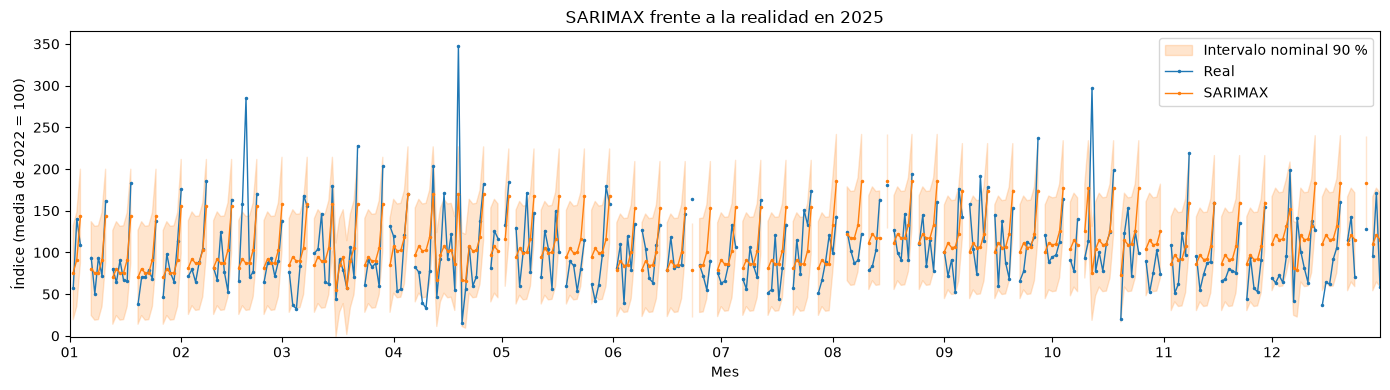

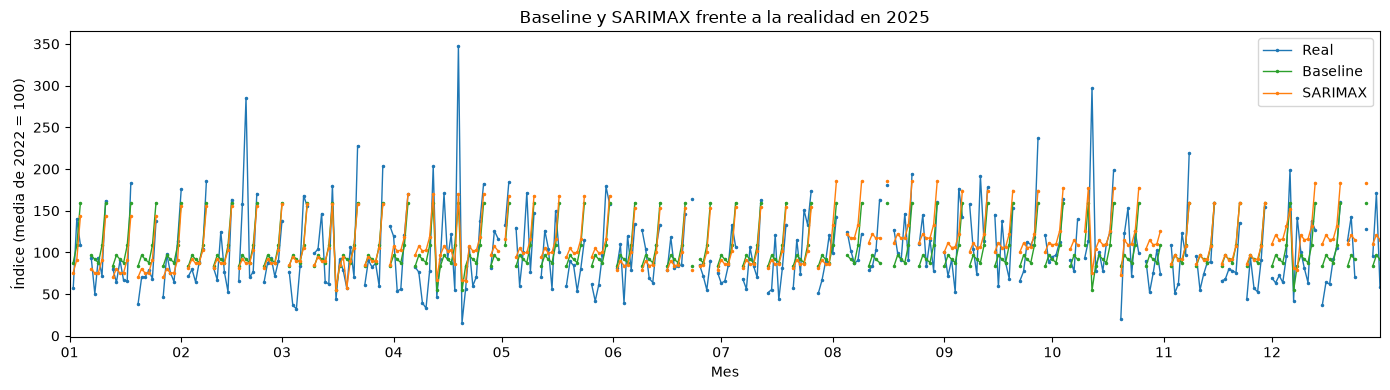

In [8]:
fechas_2025 = pd.date_range("2025-01-01", "2025-12-31", freq="D")
grafica = test_2025.set_index("fecha").reindex(fechas_2025)
valores = grafica[["indice", "sarimax", "baseline", "limite_inferior", "limite_superior"]]
limite_inferior = min(0, valores.min().min() * 1.05)
limite_superior = valores.max().max() * 1.05

fig, ax = plt.subplots(figsize=(14, 4))
ax.fill_between(grafica.index, grafica["limite_inferior"], grafica["limite_superior"],
                color="C1", alpha=0.20, label="Intervalo nominal 90 %")
ax.plot(grafica.index, grafica["indice"], label="Real", color="C0", marker=".", markersize=3, linewidth=1)
ax.plot(grafica.index, grafica["sarimax"], label="SARIMAX", color="C1", marker=".", markersize=3, linewidth=1)
ax.set(title="SARIMAX frente a la realidad en 2025", xlabel="Mes", ylabel="Índice (media de 2022 = 100)",
       ylim=(limite_inferior, limite_superior), xlim=(fechas_2025[0], fechas_2025[-1]))
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m"))
ax.legend()
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(14, 4))
for columna, etiqueta, color in [("indice", "Real", "C0"), ("baseline", "Baseline", "C2"), ("sarimax", "SARIMAX", "C1")]:
    ax.plot(grafica.index, grafica[columna], label=etiqueta, color=color, marker=".", markersize=3, linewidth=1)
ax.set(title="Baseline y SARIMAX frente a la realidad en 2025", xlabel="Mes", ylabel="Índice (media de 2022 = 100)",
       ylim=(limite_inferior, limite_superior), xlim=(fechas_2025[0], fechas_2025[-1]))
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m"))
ax.legend()
fig.tight_layout()
plt.show()

## 8. Comparación de configuraciones estacionales

Comparamos cuatro configuraciones manteniendo las mismas variables exógenas de día de la semana, mes y festivo. Las variables de mes representan el comportamiento medio de cada mes observado en los años de entrenamiento. El componente estacional con periodo 7 estudia además la dependencia de los errores entre días separados siete **días naturales**; no son siete días abiertos.

| Configuración | Orden `(p,d,q)` | Orden estacional `(P,D,Q,s)` | Idea |
|---|---|---|---|
| Inicial | `(1,0,0)` | `(0,0,0,0)` | Autorregresión diaria; sin componente SAR estacional. |
| SAR semanal | `(0,0,0)` | `(1,0,0,7)` | Autorregresión estacional semanal. |
| AR + SAR semanal | `(1,0,0)` | `(1,0,0,7)` | Autorregresión diaria y semanal. |
| AR + SMA semanal | `(1,0,0)` | `(0,0,1,7)` | Autorregresión diaria y media móvil estacional. |

Mantenemos `d=0` y `D=0` en esta primera comparación. Las fechas cerradas siguen siendo valores no observados; todos los modelos predicen el periodo completo sin consultar sus ventas reales. Si un ajuste no converge, la ejecución se detiene y muestra la configuración y el corte afectado. Ajustar todas las configuraciones puede tardar varios minutos.

Primero comparamos los ocho cortes trimestrales y los dos anuales de 2023–2024. Para elegir una configuración de forma reproducible, usamos el **WAPE conjunto de las dos validaciones anuales**: coincide con el horizonte de un año que queremos estudiar. En caso de empate, usamos el WAPE conjunto trimestral. Esto no demuestra que la configuración elegida vaya a ser la mejor en otros años.

In [9]:
CONFIGURACIONES = {
    "Inicial": ((1, 0, 0), (0, 0, 0, 0)),
    "SAR semanal": ((0, 0, 0), (1, 0, 0, 7)),
    "AR + SAR semanal": ((1, 0, 0), (1, 0, 0, 7)),
    "AR + SMA semanal": ((1, 0, 0), (0, 0, 1, 7)),
}

# Los resultados de la configuración inicial ya se calcularon en las secciones anteriores.
validaciones_configuracion = {
    "Inicial": {"trimestral": validacion_trimestral, "anual": validacion_anual},
}
for nombre, (orden, orden_estacional) in CONFIGURACIONES.items():
    if nombre == "Inicial":
        continue
    print(f"Validando {nombre}...")
    resultados_cortes = []
    for trimestre in pd.period_range("2023Q1", "2024Q4", freq="Q"):
        resultado, _ = evaluar_periodo(
            datos, trimestre.start_time, trimestre.end_time.normalize(), orden, orden_estacional
        )
        resultado["trimestre"] = str(trimestre)
        resultados_cortes.append(resultado)
    resultados_anios = []
    for anio in [2023, 2024]:
        resultado, _ = evaluar_periodo(datos, f"{anio}-01-01", f"{anio}-12-31", orden, orden_estacional)
        resultado["anio_validacion"] = anio
        resultados_anios.append(resultado)
    validaciones_configuracion[nombre] = {
        "trimestral": pd.concat(resultados_cortes, ignore_index=True),
        "anual": pd.concat(resultados_anios, ignore_index=True),
    }

filas_configuraciones = []
filas_por_anio = []
for nombre, validaciones in validaciones_configuracion.items():
    for horizonte, resultado in validaciones.items():
        if not resultado["fecha"].equals(validaciones_configuracion["Inicial"][horizonte]["fecha"]):
            raise ValueError(f"Los días evaluados de {nombre} no coinciden con la configuración inicial.")
        filas_configuraciones.append({"Configuración": nombre, "Horizonte": horizonte,
                                      **metricas(resultado["indice"], resultado["sarimax"]).to_dict()})
    for anio, grupo in validaciones["anual"].groupby("anio_validacion"):
        filas_por_anio.append({"Año": anio, "Configuración": nombre,
                               **metricas(grupo["indice"], grupo["sarimax"]).to_dict()})

for horizonte, resultado in validaciones_configuracion["Inicial"].items():
    filas_configuraciones.append({"Configuración": "Baseline: mediana día semanal", "Horizonte": horizonte,
                                  **metricas(resultado["indice"], resultado["baseline"]).to_dict()})
tabla_configuraciones = pd.DataFrame(filas_configuraciones).set_index(["Horizonte", "Configuración"])
print("Errores conjuntos por horizonte y configuración:")
display(tabla_configuraciones.round(2))
print("Errores de validación anual por año:")
display(pd.DataFrame(filas_por_anio).set_index(["Año", "Configuración"]).round(2))

wape_anual = tabla_configuraciones.loc["anual", "WAPE (%)"].loc[list(CONFIGURACIONES)]
wape_trimestral = tabla_configuraciones.loc["trimestral", "WAPE (%)"].loc[list(CONFIGURACIONES)]
ranking = pd.DataFrame({"WAPE anual": wape_anual, "WAPE trimestral": wape_trimestral})
ranking = ranking.sort_values(["WAPE anual", "WAPE trimestral"], kind="stable")
configuracion_elegida = ranking.index[0]
print(f"Configuración elegida usando solo validación: {configuracion_elegida}")
display(ranking.round(2))

Validando SAR semanal...


Validando AR + SAR semanal...


Validando AR + SMA semanal...


Errores conjuntos por horizonte y configuración:


,,Días abiertos,MAE (puntos de índice),MAPE (%),WAPE (%),Sesgo (puntos de índice)
Horizonte,Configuración,,,,,
trimestral,Inicial,618.0,27.40,31.68,24.52,-4.56
anual,Inicial,618.0,27.51,32.10,24.61,-4.82
trimestral,SAR semanal,618.0,27.43,31.72,24.54,-4.56
anual,SAR semanal,618.0,27.53,32.13,24.63,-4.77
trimestral,AR + SAR semanal,618.0,27.42,31.73,24.53,-4.55
anual,AR + SAR semanal,618.0,27.51,32.11,24.61,-4.81
trimestral,AR + SMA semanal,618.0,27.40,31.70,24.52,-4.56
anual,AR + SMA semanal,618.0,27.52,32.13,24.62,-4.82
trimestral,Baseline: mediana día semanal,618.0,29.14,31.89,26.07,-9.17


Errores de validación anual por año:


,,Días abiertos,MAE (puntos de índice),MAPE (%),WAPE (%),Sesgo (puntos de índice)
Año,Configuración,,,,,
2023,Inicial,311.0,25.49,35.55,22.87,-6.60
2024,Inicial,307.0,29.55,28.60,26.36,-3.03
2023,SAR semanal,311.0,25.52,35.58,22.89,-6.54
2024,SAR semanal,307.0,29.56,28.63,26.37,-2.99
2023,AR + SAR semanal,311.0,25.51,35.58,22.88,-6.57
2024,AR + SAR semanal,307.0,29.54,28.59,26.35,-3.02
2023,AR + SMA semanal,311.0,25.51,35.61,22.88,-6.59
2024,AR + SMA semanal,307.0,29.56,28.61,26.37,-3.03


Configuración elegida usando solo validación: Inicial


,WAPE anual,WAPE trimestral
Configuración,,
Inicial,24.61,24.52
AR + SAR semanal,24.61,24.53
AR + SMA semanal,24.62,24.52
SAR semanal,24.63,24.54


### Comparación retrospectiva de 2025

Una vez elegida la configuración mediante 2023–2024, predecimos 2025 completo para cada una y las comparamos con el baseline sobre los mismos días abiertos. Se muestran MAE, MAPE, WAPE, sesgo y cobertura observada y anchura de sus intervalos del 90 %.

Los intervalos de SARIMAX son nominales y dependen de sus hipótesis; el intervalo del baseline usa los errores de validación, como se explicó antes. La cobertura no está garantizada. Como ya hemos consultado 2025, esta comparación es retrospectiva y no constituye una prueba completamente ciega; no se utiliza para elegir la configuración.

In [10]:
resultados_config_2025 = {"Inicial": test_2025}
for nombre, (orden, orden_estacional) in CONFIGURACIONES.items():
    if nombre != "Inicial":
        resultado, _ = evaluar_periodo(datos, "2025-01-01", "2025-12-31", orden, orden_estacional)
        if not resultado["fecha"].equals(test_2025["fecha"]):
            raise ValueError(f"Los días evaluados de {nombre} no coinciden con el baseline.")
        resultados_config_2025[nombre] = resultado

filas_test_config = []
for nombre, resultado in resultados_config_2025.items():
    errores = metricas(resultado["indice"], resultado["sarimax"])
    intervalo = resumen_intervalo(resultado["indice"], resultado["limite_inferior"], resultado["limite_superior"])
    filas_test_config.append(pd.concat([errores, intervalo.drop("Días abiertos")]).rename(nombre))
errores_baseline_2025 = metricas(test_2025["indice"], test_2025["baseline"])
intervalo_baseline_2025 = resumen_intervalo(
    test_2025["indice"], test_2025["baseline_inferior"], test_2025["baseline_superior"]
)
filas_test_config.append(pd.concat([errores_baseline_2025, intervalo_baseline_2025.drop("Días abiertos")])
                         .rename("Baseline: mediana día semanal"))
tabla_test_config = pd.DataFrame(filas_test_config)
tabla_test_config.index.name = "Configuración"
display(tabla_test_config.round(2))
print(f"Configuración seleccionada por validación: {configuracion_elegida}")

,Días abiertos,MAE (puntos de índice),MAPE (%),WAPE (%),Sesgo (puntos de índice),Cobertura observada (%),Anchura media (puntos de índice)
Configuración,,,,,,,
Inicial,308.0,28.54,34.78,27.89,7.60,89.29,112.53
SAR semanal,308.0,28.49,34.69,27.84,7.52,89.61,112.48
AR + SAR semanal,308.0,28.51,34.74,27.86,7.63,89.29,112.33
AR + SMA semanal,308.0,28.52,34.74,27.86,7.59,89.61,112.46
Baseline: mediana día semanal,308.0,27.32,32.12,26.70,1.61,95.13,127.62


Configuración seleccionada por validación: Inicial


### Gráficas de las cuatro configuraciones

Cada gráfica muestra los índices reales y previstos de los días abiertos de 2025 y el intervalo nominal de SARIMAX del 90 %. Los cierres son huecos; las cuatro gráficas usan la misma escala vertical. Los límites pueden ser negativos, porque la distribución de predicción no está acotada.

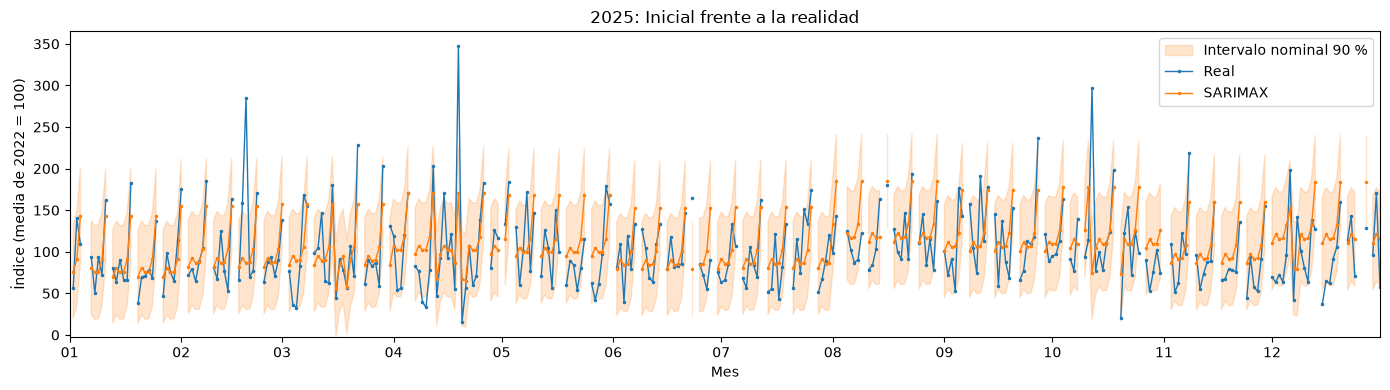

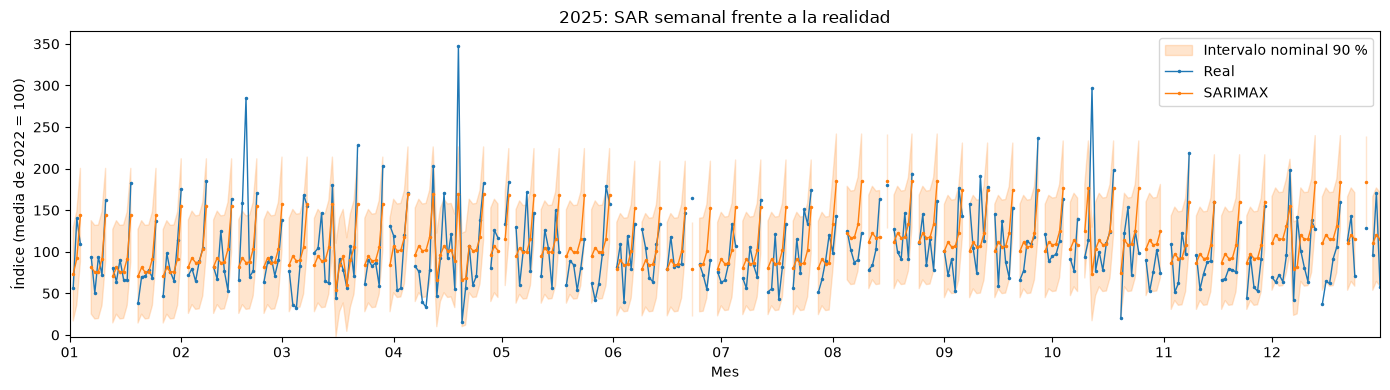

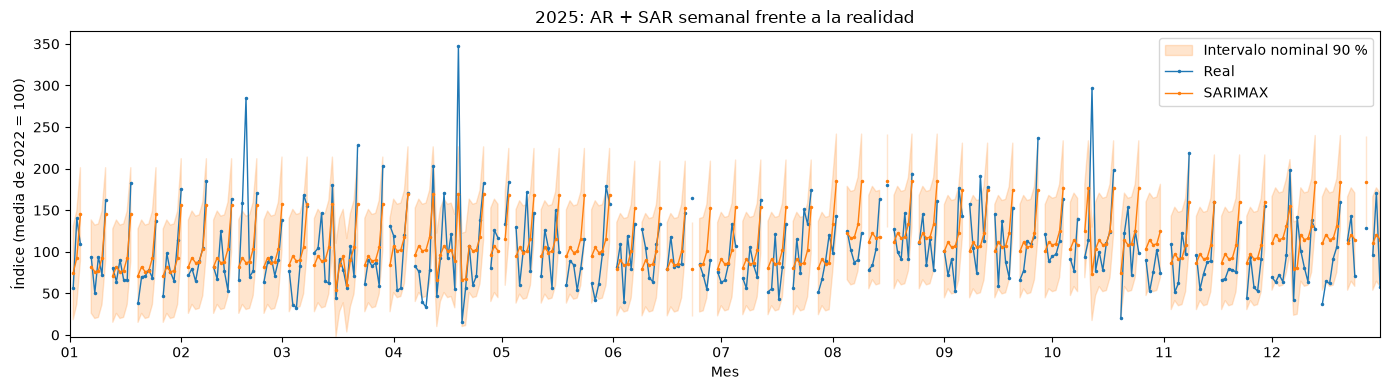

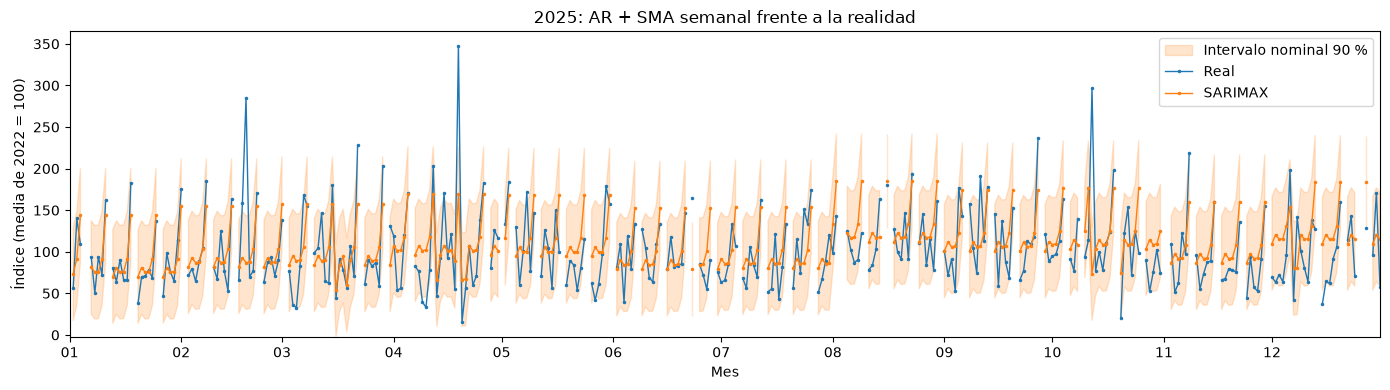

In [11]:
limite_graficas_min = min(
    0, min(resultado[["indice", "sarimax", "limite_inferior"]].min().min()
           for resultado in resultados_config_2025.values()) * 1.05
)
limite_graficas_max = max(
    resultado[["indice", "sarimax", "limite_superior"]].max().max()
    for resultado in resultados_config_2025.values()
) * 1.05
for nombre, resultado in resultados_config_2025.items():
    grafica_config = resultado.set_index("fecha").reindex(fechas_2025)
    fig, ax = plt.subplots(figsize=(14, 4))
    ax.fill_between(grafica_config.index, grafica_config["limite_inferior"], grafica_config["limite_superior"],
                    color="C1", alpha=0.20, label="Intervalo nominal 90 %")
    ax.plot(grafica_config.index, grafica_config["indice"], label="Real", color="C0",
            marker=".", markersize=3, linewidth=1)
    ax.plot(grafica_config.index, grafica_config["sarimax"], label="SARIMAX", color="C1",
            marker=".", markersize=3, linewidth=1)
    ax.set(title=f"2025: {nombre} frente a la realidad", xlabel="Mes",
           ylabel="Índice (media de 2022 = 100)", ylim=(limite_graficas_min, limite_graficas_max),
           xlim=(fechas_2025[0], fechas_2025[-1]))
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m"))
    ax.legend()
    fig.tight_layout()
    plt.show()

## 9. Prueba: sábados en temporada alta

El SARIMAX inicial suma un efecto de día de la semana y otro de mes, pero no distingue si el efecto de ser sábado cambia según la temporada. Para probarlo añadimos **una sola variable de interacción**: vale 1 cuando la fecha es sábado de agosto, septiembre, octubre o diciembre, y 0 en los demás casos. Esos meses se han elegido a partir del EDA, que ya incluía 2025, por lo que la prueba no es completamente ciega.

El resto de la configuración se mantiene igual: `(1,0,0) × (0,0,0,0)`, con día de la semana, mes y festivo. La nueva variable solo utiliza el calendario conocido de antemano. El coeficiente estimado describe una diferencia adicional para esos sábados, no un efecto causal.

Comparamos el modelo original, el modelo con interacción y el baseline sobre los mismos días abiertos y cortes temporales. Seleccionamos entre los dos SARIMAX por **WAPE conjunto de validación anual de 2023–2024**, sin usar las ventas reales de 2025 para elegir. También mostramos los resultados de los sábados de temporada alta y los recuentos: hay menos observaciones y sus métricas pueden ser inestables.

In [ ]:
cortes_interaccion = []
for trimestre in pd.period_range("2023Q1", "2024Q4", freq="Q"):
    resultado, _ = evaluar_periodo(
        datos, trimestre.start_time, trimestre.end_time.normalize(), interaccion_sabado=True
    )
    resultado["trimestre"] = str(trimestre)
    cortes_interaccion.append(resultado)
validacion_trimestral_interaccion = pd.concat(cortes_interaccion, ignore_index=True)

anios_interaccion = []
for anio in [2023, 2024]:
    resultado, _ = evaluar_periodo(datos, f"{anio}-01-01", f"{anio}-12-31", interaccion_sabado=True)
    resultado["anio_validacion"] = anio
    anios_interaccion.append(resultado)
validacion_anual_interaccion = pd.concat(anios_interaccion, ignore_index=True)

def comparar_interaccion(original, interaccion):
    if not original["fecha"].equals(interaccion["fecha"]) or not original["indice"].equals(interaccion["indice"]):
        raise ValueError("Los modelos no se evalúan sobre los mismos días abiertos.")
    return pd.DataFrame({
        "Baseline: mediana día semanal": metricas(original["indice"], original["baseline"]),
        "SARIMAX original": metricas(original["indice"], original["sarimax"]),
        "SARIMAX con interacción": metricas(interaccion["indice"], interaccion["sarimax"]),
    }).T

def es_sabado_temporada_alta(fechas):
    return fechas.dt.day_of_week.eq(5) & fechas.dt.month.isin(MESES_TEMPORADA_ALTA)

print("Validación trimestral conjunta:")
display(comparar_interaccion(validacion_trimestral, validacion_trimestral_interaccion).round(2))
print("Validación anual conjunta:")
tabla_interaccion_anual = comparar_interaccion(validacion_anual, validacion_anual_interaccion)
display(tabla_interaccion_anual.round(2))

filas_anuales_interaccion = []
for anio in [2023, 2024]:
    original = validacion_anual.loc[validacion_anual["anio_validacion"].eq(anio)].reset_index(drop=True)
    nuevo = validacion_anual_interaccion.loc[validacion_anual_interaccion["anio_validacion"].eq(anio)].reset_index(drop=True)
    resumen = comparar_interaccion(original, nuevo)
    resumen["Año"] = anio
    filas_anuales_interaccion.append(resumen.reset_index(names="Modelo"))
print("Validación anual por año:")
display(pd.concat(filas_anuales_interaccion, ignore_index=True).set_index(["Año", "Modelo"]).round(2))

mascara = es_sabado_temporada_alta(validacion_anual["fecha"])
if not mascara.any():
    raise ValueError("No hay sábados abiertos de temporada alta para evaluar en la validación anual.")
print("Sábados abiertos de temporada alta en la validación anual conjunta:")
display(comparar_interaccion(
    validacion_anual.loc[mascara].reset_index(drop=True),
    validacion_anual_interaccion.loc[mascara].reset_index(drop=True),
).round(2))

wape_original = tabla_interaccion_anual.loc["SARIMAX original", "WAPE (%)"]
wape_interaccion = tabla_interaccion_anual.loc["SARIMAX con interacción", "WAPE (%)"]
modelo_interaccion_elegido = "SARIMAX con interacción" if wape_interaccion < wape_original else "SARIMAX original"
print(f"Modelo elegido por WAPE anual de validación: {modelo_interaccion_elegido}")

Validación trimestral conjunta:


,Días abiertos,MAE (puntos de índice),MAPE (%),WAPE (%),Sesgo (puntos de índice)
Baseline: mediana día semanal,618.0,29.14,31.89,26.07,-9.17
SARIMAX original,618.0,27.40,31.68,24.52,-4.56
SARIMAX con interacción,618.0,27.54,31.82,24.64,-4.56


Validación anual conjunta:


,Días abiertos,MAE (puntos de índice),MAPE (%),WAPE (%),Sesgo (puntos de índice)
Baseline: mediana día semanal,618.0,29.20,32.34,26.13,-8.51
SARIMAX original,618.0,27.51,32.10,24.61,-4.82
SARIMAX con interacción,618.0,27.61,32.10,24.70,-4.83


Validación anual por año:


Días abiertos  MAE (puntos de índice)  \
Año  Modelo                                                                 
2023 Baseline: mediana día semanal          311.0                   28.65   
     SARIMAX original                       311.0                   25.49   
     SARIMAX con interacción                311.0                   25.71   
2024 Baseline: mediana día semanal          307.0                   29.76   
     SARIMAX original                       307.0                   29.55   
     SARIMAX con interacción                307.0                   29.54   

                                    MAPE (%)  WAPE (%)  \
Año  Modelo                                              
2023 Baseline: mediana día semanal     36.87     25.70   
     SARIMAX original                  35.55     22.87   
     SARIMAX con interacción           35.56     23.06   
2024 Baseline: mediana día semanal     27.75     26.55   
     SARIMAX original                  28.60     26.36   
     SARIMAX con interacción           28.60     26.35   

                                    Sesgo (puntos de índice)  
Año  Modelo                                                   
2023 Baseline: mediana día semanal                     -9.87  
     SARIMAX original                                  -6.60  
     SARIMAX con interacción                           -6.58  
2024 Baseline: mediana día semanal                     -7.14  
     SARIMAX original                                  -3.03  
     SARIMAX con interacción                           -3.05

Sábados abiertos de temporada alta en la validación anual conjunta:


,Días abiertos,MAE (puntos de índice),MAPE (%),WAPE (%),Sesgo (puntos de índice)
Baseline: mediana día semanal,35.0,51.46,25.53,27.14,-38.66
SARIMAX original,35.0,44.39,23.74,23.41,-19.99
SARIMAX con interacción,35.0,41.53,23.12,21.90,-11.73


Modelo elegido por WAPE anual de validación: SARIMAX original


### Comparación retrospectiva de 2025

Con la elección ya realizada usando la validación, ajustamos la variante con interacción con 2022–2024 y predecimos 2025 completo de una vez. Mostramos los errores y la cobertura de los intervalos nominales del 90 % junto con las del SARIMAX original y el baseline. Los intervalos utilizan métodos diferentes y su cobertura futura no está garantizada.

Desglosamos también los sábados abiertos de temporada alta. El coeficiente adicional se ha estimado solo con los datos anteriores a 2025, pero no debe interpretarse como causal. Puesto que ya exploramos 2025 y sus patrones, este resultado es una comparación retrospectiva y no una prueba completamente ciega.

In [ ]:
test_interaccion, ajuste_interaccion = evaluar_periodo(
    datos, "2025-01-01", "2025-12-31", interaccion_sabado=True
)
print("Errores de los días abiertos de 2025:")
display(comparar_interaccion(test_2025, test_interaccion).round(2))

mascara_test = es_sabado_temporada_alta(test_2025["fecha"])
if not mascara_test.any():
    raise ValueError("No hay sábados abiertos de temporada alta para evaluar en 2025.")
print("Errores en sábados abiertos de temporada alta de 2025:")
display(comparar_interaccion(
    test_2025.loc[mascara_test].reset_index(drop=True),
    test_interaccion.loc[mascara_test].reset_index(drop=True),
).round(2))

intervalos_interaccion_2025 = pd.DataFrame({
    "Baseline: mediana día semanal": resumen_intervalo(
        test_2025["indice"], test_2025["baseline_inferior"], test_2025["baseline_superior"]
    ),
    "SARIMAX original": resumen_intervalo(
        test_2025["indice"], test_2025["limite_inferior"], test_2025["limite_superior"]
    ),
    "SARIMAX con interacción": resumen_intervalo(
        test_interaccion["indice"], test_interaccion["limite_inferior"], test_interaccion["limite_superior"]
    ),
}).T
print("Cobertura y anchura de los intervalos:")
display(intervalos_interaccion_2025.round(2))
coeficiente = ajuste_interaccion.params.loc["sabado_temporada_alta"]
print(f"Diferencia adicional estimada para sábado en temporada alta: {coeficiente:.2f} puntos de índice")
print(f"Modelo elegido por validación: {modelo_interaccion_elegido}")

Errores de los días abiertos de 2025:


,Días abiertos,MAE (puntos de índice),MAPE (%),WAPE (%),Sesgo (puntos de índice)
Baseline: mediana día semanal,308.0,27.32,32.12,26.70,1.61
SARIMAX original,308.0,28.54,34.78,27.89,7.60
SARIMAX con interacción,308.0,28.66,34.88,28.00,7.60


Errores en sábados abiertos de temporada alta de 2025:


,Días abiertos,MAE (puntos de índice),MAPE (%),WAPE (%),Sesgo (puntos de índice)
Baseline: mediana día semanal,17.0,28.30,19.07,17.82,0.77
SARIMAX original,17.0,36.53,26.36,23.00,19.83
SARIMAX con interacción,17.0,38.79,28.33,24.42,25.07


Cobertura y anchura de los intervalos:


,Días abiertos,Cobertura observada (%),Anchura media (puntos de índice)
Baseline: mediana día semanal,308.0,95.13,127.62
SARIMAX original,308.0,89.29,112.53
SARIMAX con interacción,308.0,89.61,112.32


Diferencia adicional estimada para sábado en temporada alta: 9.48 puntos de índice
Modelo elegido por validación: SARIMAX original


### Predicciones frente a la realidad

Comparamos las predicciones diarias del SARIMAX original y de la variante con interacción con la realidad de los días abiertos de 2025. La banda representa el intervalo nominal del 90 % de la variante con interacción. Los cierres aparecen como huecos y los valores son índices, no euros.

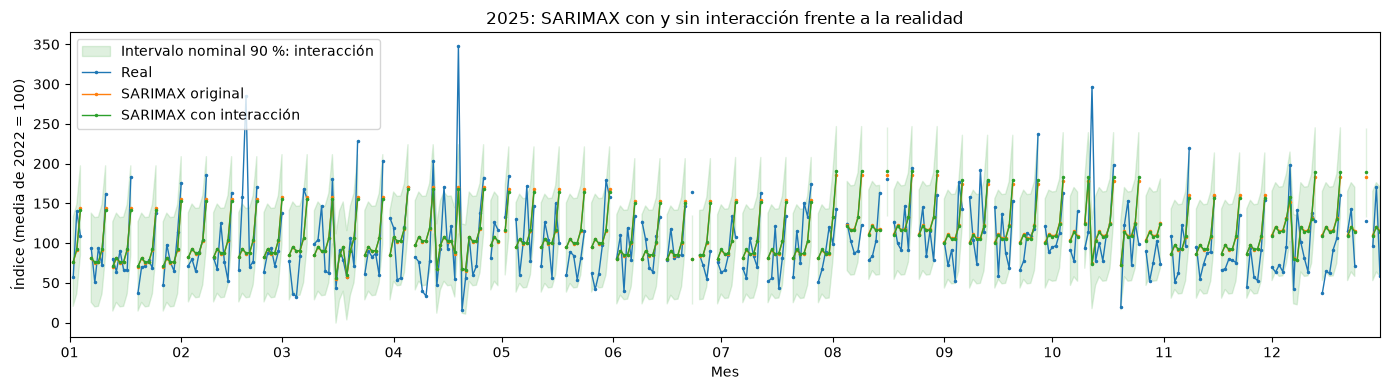

In [ ]:
fechas_interaccion_2025 = pd.date_range("2025-01-01", "2025-12-31", freq="D")
grafica_interaccion = test_interaccion.set_index("fecha").reindex(fechas_interaccion_2025)
grafica_original = test_2025.set_index("fecha").reindex(fechas_interaccion_2025)
fig, ax = plt.subplots(figsize=(14, 4))
ax.fill_between(grafica_interaccion.index, grafica_interaccion["limite_inferior"],
                grafica_interaccion["limite_superior"], color="C2", alpha=0.15,
                label="Intervalo nominal 90 %: interacción")
ax.plot(grafica_interaccion.index, grafica_interaccion["indice"], label="Real", color="C0",
        marker=".", markersize=3, linewidth=1)
ax.plot(grafica_original.index, grafica_original["sarimax"], label="SARIMAX original", color="C1",
        marker=".", markersize=3, linewidth=1)
ax.plot(grafica_interaccion.index, grafica_interaccion["sarimax"], label="SARIMAX con interacción", color="C2",
        marker=".", markersize=3, linewidth=1)
ax.set(title="2025: SARIMAX con y sin interacción frente a la realidad", xlabel="Mes",
       ylabel="Índice (media de 2022 = 100)", xlim=(fechas_interaccion_2025[0], fechas_interaccion_2025[-1]))
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m"))
ax.legend()
fig.tight_layout()
plt.show()

## 10. Ventanas móviles y entrenamiento sin 2022

Comparamos el SARIMAX original, sin interacción, con tres historiales: **expansivo** (todo lo disponible), **último año** y **últimos dos años** antes de cada corte. La ventana se desplaza en cada corte histórico; dentro de cada horizonte no se reentrena ni se utilizan sus ventas para predecir.

Para validar los tres historiales con ventanas completas usamos los cuatro trimestres y el año completo de 2024. En la validación anual de 2024, el historial expansivo y el de dos años son idénticos (2022–2023); solo hay un año de validación anual para comparar el historial de un año (2023). Los cortes trimestrales tienen un horizonte distinto al anual y comparten datos de entrenamiento.

Después comparamos retrospectivamente 2025: todo el historial (2022–2024), dos años (2023–2024, sin entrenar con 2022) y un año (2024). Las predicciones se generan de una sola vez antes de compararlas con los días abiertos reales. El índice sigue usando la media de 2022 como referencia, incluso cuando 2022 no interviene en el ajuste. El baseline es siempre la mediana semanal entrenada con todo el historial previo, para mantener una referencia común.

**2025 ya se ha explorado**, por lo que esta comparación no es una prueba ciega ni permite estimar imparcialmente el rendimiento de una ventana elegida mirando esos resultados. Los intervalos son nominales al 90 % y su cobertura observada no garantiza la cobertura futura.

In [ ]:
def evaluar_ventanas(inicio, fin, expansiva):
    inicio, fin = pd.Timestamp(inicio), pd.Timestamp(fin)
    resultados = {"SARIMAX expansivo": expansiva.reset_index(drop=True)}
    for anios, nombre in [(1, "SARIMAX último año"), (2, "SARIMAX últimos dos años")]:
        desde = inicio - pd.DateOffset(years=anios)
        if datos.index.min() > desde:
            raise ValueError(f"No hay {anios} años completos antes de {inicio.date()}.")
        ventana = datos.loc[desde:fin]
        resultado, _ = evaluar_periodo(ventana, inicio, fin)
        resultado = resultado.reset_index(drop=True)
        if not resultado["fecha"].equals(resultados["SARIMAX expansivo"]["fecha"]) or not resultado["indice"].equals(resultados["SARIMAX expansivo"]["indice"]):
            raise ValueError("Las ventanas no se evalúan sobre los mismos días abiertos.")
        resultados[nombre] = resultado
    return resultados

def comparar_ventanas(resultados):
    referencia = resultados["SARIMAX expansivo"]
    filas = {"Baseline: mediana día semanal": metricas(referencia["indice"], referencia["baseline"])}
    for nombre, resultado in resultados.items():
        if not resultado["fecha"].equals(referencia["fecha"]) or not resultado["indice"].equals(referencia["indice"]):
            raise ValueError("Las ventanas no se evalúan sobre los mismos días abiertos.")
        filas[nombre] = metricas(resultado["indice"], resultado["sarimax"])
    return pd.DataFrame(filas).T

ventanas_trimestrales = {}
filas_ventanas_trimestrales = []
for trimestre in pd.period_range("2024Q1", "2024Q4", freq="Q"):
    original = validacion_trimestral.loc[validacion_trimestral["trimestre"].eq(str(trimestre))]
    resultados = evaluar_ventanas(trimestre.start_time, trimestre.end_time.normalize(), original)
    ventanas_trimestrales[str(trimestre)] = resultados
    resumen = comparar_ventanas(resultados).reset_index(names="Modelo")
    resumen["Trimestre"] = str(trimestre)
    filas_ventanas_trimestrales.append(resumen)

conjunto_ventanas = {
    nombre: pd.concat([resultados[nombre] for resultados in ventanas_trimestrales.values()], ignore_index=True)
    for nombre in ventanas_trimestrales["2024Q1"]
}
print("Validación trimestral conjunta de 2024:")
display(comparar_ventanas(conjunto_ventanas).round(2))
print("Validación por trimestre:")
display(pd.concat(filas_ventanas_trimestrales, ignore_index=True).set_index(["Trimestre", "Modelo"]).round(2))

original_2024 = validacion_anual.loc[validacion_anual["anio_validacion"].eq(2024)]
ventanas_anuales_2024 = evaluar_ventanas("2024-01-01", "2024-12-31", original_2024)
print("Validación anual de 2024:")
display(comparar_ventanas(ventanas_anuales_2024).round(2))

Validación trimestral conjunta de 2024:


,Días abiertos,MAE (puntos de índice),MAPE (%),WAPE (%),Sesgo (puntos de índice)
Baseline: mediana día semanal,307.0,29.72,27.50,26.51,-7.94
SARIMAX expansivo,307.0,29.51,28.55,26.33,-2.90
SARIMAX último año,307.0,29.75,29.39,26.54,0.64
SARIMAX últimos dos años,307.0,29.48,28.49,26.30,-2.70


Validación por trimestre:


Días abiertos  \
Trimestre Modelo                                         
2024Q1    Baseline: mediana día semanal           77.0   
          SARIMAX expansivo                       77.0   
          SARIMAX último año                      77.0   
          SARIMAX últimos dos años                77.0   
2024Q2    Baseline: mediana día semanal           76.0   
          SARIMAX expansivo                       76.0   
          SARIMAX último año                      76.0   
          SARIMAX últimos dos años                76.0   
2024Q3    Baseline: mediana día semanal           78.0   
          SARIMAX expansivo                       78.0   
          SARIMAX último año                      78.0   
          SARIMAX últimos dos años                78.0   
2024Q4    Baseline: mediana día semanal           76.0   
          SARIMAX expansivo                       76.0   
          SARIMAX último año                      76.0   
          SARIMAX últimos dos años                76.0   

                                         MAE (puntos de índice)  MAPE (%)  \
Trimestre Modelo                                                            
2024Q1    Baseline: mediana día semanal                   28.70     28.72   
          SARIMAX expansivo                               27.77     23.58   
          SARIMAX último año                              26.93     24.29   
          SARIMAX últimos dos años                        27.77     23.58   
2024Q2    Baseline: mediana día semanal                   28.36     27.57   
          SARIMAX expansivo                               27.57     28.08   
          SARIMAX último año                              28.33     29.36   
          SARIMAX últimos dos años                        27.46     27.91   
2024Q3    Baseline: mediana día semanal                   30.57     28.51   
          SARIMAX expansivo                               32.00     33.47   
          SARIMAX último año                              32.92     35.04   
          SARIMAX últimos dos años                        31.90     33.51   
2024Q4    Baseline: mediana día semanal                   31.23     25.13   
          SARIMAX expansivo                               30.65     29.03   
          SARIMAX último año                              30.77     28.77   
          SARIMAX últimos dos años                        30.74     28.89   

                                         WAPE (%)  Sesgo (puntos de índice)  
Trimestre Modelo                                                             
2024Q1    Baseline: mediana día semanal     26.72                     -2.52  
          SARIMAX expansivo                 25.86                    -15.39  
          SARIMAX último año                25.07                    -11.59  
          SARIMAX últimos dos años          25.86                    -15.39  
2024Q2    Baseline: mediana día semanal     25.92                     -5.96  
          SARIMAX expansivo                 25.20                     -1.77  
          SARIMAX último año                25.89                      1.90  
          SARIMAX últimos dos años          25.10                     -1.83  
2024Q3    Baseline: mediana día semanal     27.40                     -7.27  
          SARIMAX expansivo                 28.68                      7.14  
          SARIMAX último año                29.51                      9.78  
          SARIMAX últimos dos años          28.59                      7.78  
2024Q4    Baseline: mediana día semanal     26.02                    -16.10  
          SARIMAX expansivo                 25.54                     -1.67  
          SARIMAX último año                25.64                      2.38  
          SARIMAX últimos dos años          25.61                     -1.47

Validación anual de 2024:


,Días abiertos,MAE (puntos de índice),MAPE (%),WAPE (%),Sesgo (puntos de índice)
Baseline: mediana día semanal,307.0,29.76,27.75,26.55,-7.14
SARIMAX expansivo,307.0,29.55,28.60,26.36,-3.03
SARIMAX último año,307.0,29.55,29.41,26.37,0.58
SARIMAX últimos dos años,307.0,29.55,28.60,26.36,-3.03


In [ ]:
ventanas_2025 = evaluar_ventanas("2025-01-01", "2025-12-31", test_2025)
print("Historial de entrenamiento para el pronóstico anual de 2025:")
display(pd.DataFrame({
    "Inicio": [datos.index.min().date(), pd.Timestamp("2024-01-01").date(), pd.Timestamp("2023-01-01").date()],
    "Fin": [pd.Timestamp("2024-12-31").date()] * 3,
    "Días abiertos": [datos.loc[desde:"2024-12-31", "indice"].notna().sum() for desde in [datos.index.min(), "2024-01-01", "2023-01-01"]],
}, index=list(ventanas_2025)))
print("Errores en los días abiertos de 2025:")
display(comparar_ventanas(ventanas_2025).round(2))

intervalos_ventanas_2025 = {
    nombre: resumen_intervalo(resultado["indice"], resultado["limite_inferior"], resultado["limite_superior"])
    for nombre, resultado in ventanas_2025.items()
}
print("Intervalos nominales del 90 % en 2025:")
display(pd.DataFrame(intervalos_ventanas_2025).T.round(2))
print("Predicciones negativas en días abiertos:")
display(pd.Series({nombre: resultado["sarimax"].lt(0).sum() for nombre, resultado in ventanas_2025.items()}, name="Días").to_frame())

filas_ventanas_mensuales = []
for mes in range(1, 13):
    resultados_mes = {nombre: resultado.loc[resultado["fecha"].dt.month.eq(mes)].reset_index(drop=True) for nombre, resultado in ventanas_2025.items()}
    if resultados_mes["SARIMAX expansivo"].empty:
        continue
    resumen = comparar_ventanas(resultados_mes).reset_index(names="Modelo")
    resumen["Mes"] = mes
    filas_ventanas_mensuales.append(resumen)
print("Errores por mes en 2025:")
display(pd.concat(filas_ventanas_mensuales, ignore_index=True).set_index(["Mes", "Modelo"]).round(2))

Historial de entrenamiento para el pronóstico anual de 2025:


,Inicio,Fin,Días abiertos
SARIMAX expansivo,2022-01-01,2024-12-31,973
SARIMAX último año,2024-01-01,2024-12-31,307
SARIMAX últimos dos años,2023-01-01,2024-12-31,618


Errores en los días abiertos de 2025:


,Días abiertos,MAE (puntos de índice),MAPE (%),WAPE (%),Sesgo (puntos de índice)
Baseline: mediana día semanal,308.0,27.32,32.12,26.70,1.61
SARIMAX expansivo,308.0,28.54,34.78,27.89,7.60
SARIMAX último año,308.0,29.85,36.25,29.17,9.57
SARIMAX últimos dos años,308.0,29.16,35.24,28.49,9.65


Intervalos nominales del 90 % en 2025:


,Días abiertos,Cobertura observada (%),Anchura media (puntos de índice)
SARIMAX expansivo,308.0,89.29,112.53
SARIMAX último año,308.0,91.56,121.72
SARIMAX últimos dos años,308.0,90.91,116.59


Predicciones negativas en días abiertos:


,Días
SARIMAX expansivo,0
SARIMAX último año,0
SARIMAX últimos dos años,0


Errores por mes en 2025:


Días abiertos  MAE (puntos de índice)  \
Mes Modelo                                                                 
1   Baseline: mediana día semanal           25.0                   22.92   
    SARIMAX expansivo                       25.0                   18.63   
    SARIMAX último año                      25.0                   18.89   
    SARIMAX últimos dos años                25.0                   18.75   
2   Baseline: mediana día semanal           24.0                   26.56   
    SARIMAX expansivo                       24.0                   26.21   
    SARIMAX último año                      24.0                   29.14   
    SARIMAX últimos dos años                24.0                   27.81   
3   Baseline: mediana día semanal           27.0                   28.15   
    SARIMAX expansivo                       27.0                   26.71   
    SARIMAX último año                      27.0                   35.96   
    SARIMAX últimos dos años                27.0                   27.40   
4   Baseline: mediana día semanal           28.0                   32.79   
    SARIMAX expansivo                       28.0                   32.22   
    SARIMAX último año                      28.0                   30.13   
    SARIMAX últimos dos años                28.0                   30.46   
5   Baseline: mediana día semanal           26.0                   30.38   
    SARIMAX expansivo                       26.0                   32.71   
    SARIMAX último año                      26.0                   35.58   
    SARIMAX últimos dos años                26.0                   34.05   
6   Baseline: mediana día semanal           24.0                   24.54   
    SARIMAX expansivo                       24.0                   22.18   
    SARIMAX último año                      24.0                   23.09   
    SARIMAX últimos dos años                24.0                   23.54   
7   Baseline: mediana día semanal           27.0                   26.57   
    SARIMAX expansivo                       27.0                   25.53   
    SARIMAX último año                      27.0                   25.96   
    SARIMAX últimos dos años                27.0                   25.90   
8   Baseline: mediana día semanal           24.0                   22.73   
    SARIMAX expansivo                       24.0                   27.01   
    SARIMAX último año                      24.0                   23.11   
    SARIMAX últimos dos años                24.0                   26.46   
9   Baseline: mediana día semanal           26.0                   30.40   
    SARIMAX expansivo                       26.0                   30.66   
    SARIMAX último año                      26.0                   32.16   
    SARIMAX últimos dos años                26.0                   30.59   
10  Baseline: mediana día semanal           27.0                   31.84   
    SARIMAX expansivo                       27.0                   34.87   
    SARIMAX último año                      27.0                   45.62   
    SARIMAX últimos dos años                27.0                   40.90   
11  Baseline: mediana día semanal           24.0                   23.20   
    SARIMAX expansivo                       24.0                   23.47   
    SARIMAX último año                      24.0                   19.31   
    SARIMAX últimos dos años                24.0                   21.30   
12  Baseline: mediana día semanal           26.0                   26.10   
    SARIMAX expansivo                       26.0                   40.40   
    SARIMAX último año                      26.0                   36.27   
    SARIMAX últimos dos años                26.0                   40.61   

                                   MAPE (%)  WAPE (%)  \
Mes Modelo                                              
1   Baseline: mediana día semanal     33.89     26.15   
    SARIMAX expansivo                 24.10     21.25   
    SA

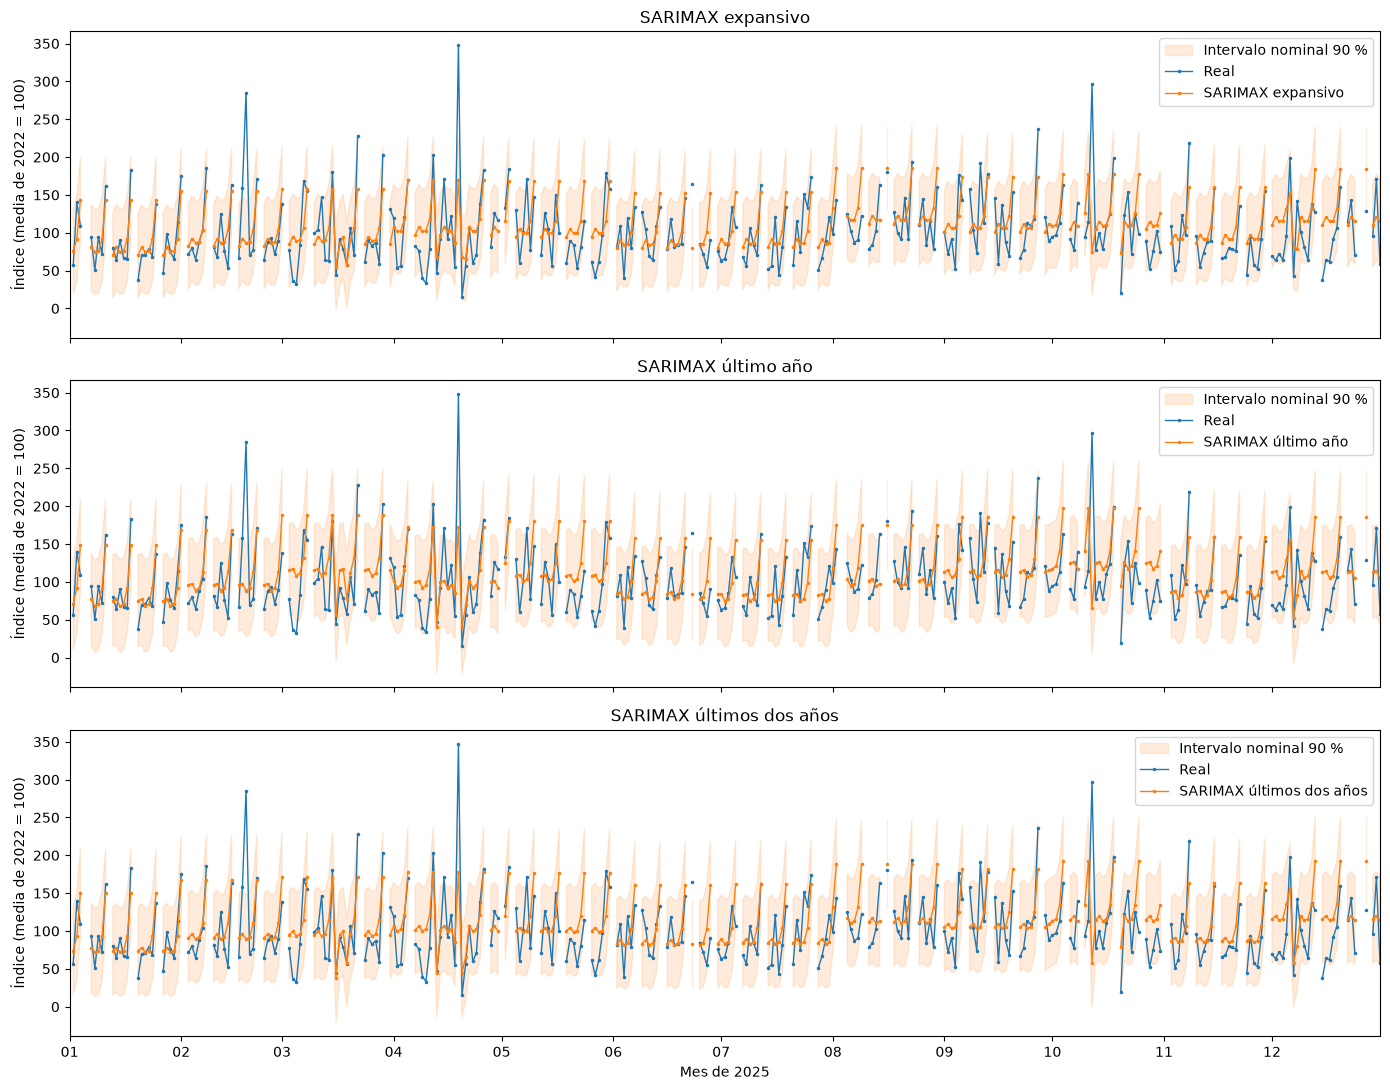

In [ ]:
fechas_ventanas_2025 = pd.date_range("2025-01-01", "2025-12-31", freq="D")
fig, ejes = plt.subplots(3, 1, figsize=(14, 11), sharex=True, sharey=True)
for ax, (nombre, resultado) in zip(ejes, ventanas_2025.items()):
    grafica_ventana = resultado.set_index("fecha").reindex(fechas_ventanas_2025)
    ax.fill_between(grafica_ventana.index, grafica_ventana["limite_inferior"], grafica_ventana["limite_superior"],
                    color="C1", alpha=0.15, label="Intervalo nominal 90 %")
    ax.plot(grafica_ventana.index, grafica_ventana["indice"], color="C0", marker=".", markersize=3, linewidth=1, label="Real")
    ax.plot(grafica_ventana.index, grafica_ventana["sarimax"], color="C1", marker=".", markersize=3, linewidth=1, label=nombre)
    ax.set(title=nombre, ylabel="Índice (media de 2022 = 100)", xlim=(fechas_ventanas_2025[0], fechas_ventanas_2025[-1]))
    ax.legend()
ejes[-1].set_xlabel("Mes de 2025")
ejes[-1].xaxis.set_major_locator(mdates.MonthLocator())
ejes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%m"))
fig.tight_layout()
plt.show()